# 00 - Quickstart: fit the example data

Fit the bundled example and look at the result: 30 one-minute epochs of Solar Orbiter
SWA-EAS data, 2023-04-04 00:50-01:19 UT, 0.33 au. No network needed.

**Runtime:** about 1.5 minutes on 4 workers.

To understand what happens inside, continue with notebook 01 and the ones after it.

In [1]:
import os
import sys
from pathlib import Path

# Single-threaded linear algebra, set before numpy is imported: the fits are
# many small least-squares problems, and this makes the numbers in this
# notebook identical to those of the batch runner (which spawns 1-thread workers).
for name in ('OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS', 'NUMEXPR_NUM_THREADS'):
    os.environ.setdefault(name, '1')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Repository root = the first parent directory that contains src/evdf_poisson
REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src' / 'evdf_poisson').is_dir())
sys.path.insert(0, str(REPO_ROOT / 'src'))

CALIBRATION_DIR = REPO_ROOT / 'examples' / 'example_data'          # EAS geometric factors, head geometry, scpot table
EXAMPLE_DIR = CALIBRATION_DIR / 'poisson_2023-04-04'                # the 30-epoch example subset
EXAMPLE_FILE = EXAMPLE_DIR / 'VDF_eas_forFitting_20230404005008_20230404011908_1min.h5'
RESULTS_DIR = REPO_ROOT / 'results' / 'fitting' / 'example_run_poisson'       # reference fit of the subset
DAYS_DIR = REPO_ROOT / 'results' / 'fitting' / 'example_days_2023-04-04_05'   # reference fit of the two full days
GEOMETRY_FILE = CALIBRATION_DIR / 'eas_head_geometry.npz'
print('repository:', REPO_ROOT)

repository: /disk/plasma/xw2/SO-EAS-eVDF_Fitting


## 1. Fit every epoch of the example file

`runFiles` runs the whole pipeline on every `VDF_eas_forFitting_*.h5` file of a directory:

1. strahl detection from the pitch-angle distribution (PAD),
2. initial guesses from the data,
3. staged Poisson fit: core -> halo -> strahl -> joint,
4. physical parameters and fit-quality metrics.

It writes one CSV per file, a merged `summary.csv` and, with `plotEvery=1`, a diagnostic
figure per epoch. The break energies are read from the `*_two_population_crossing.csv`
file next to the data (notebook 03).

In [2]:
from evdf_poisson.runner import runFiles

summary = runFiles(EXAMPLE_DIR, RESULTS_DIR, workers=4, plotEvery=1, resume=False)

2026-10-05 18:39:37  1 files, 4 workers, objective=poisson, halo drift free -> /disk/plasma/xw2/SO-EAS-eVDF_Fitting/results/fitting/example_run_poisson


2026-10-05 18:39:38  [1/1] VDF_eas_forFitting_20230404005008_20230404011908_1min.h5 (30 epochs)


/disk/anaconda/xw2/miniconda3/envs/SunSolarWind/lib/python3.10/site-packages/uncertainties/core.py:1024: UserWarning: Using UFloat objects with std_dev==0 may give unexpected results.
  warn("Using UFloat objects with std_dev==0 may give unexpected results.")
/disk/anaconda/xw2/miniconda3/envs/SunSolarWind/lib/python3.10/site-packages/uncertainties/core.py:1024: UserWarning: Using UFloat objects with std_dev==0 may give unexpected results.
  warn("Using UFloat objects with std_dev==0 may give unexpected results.")
/disk/anaconda/xw2/miniconda3/envs/SunSolarWind/lib/python3.10/site-packages/uncertainties/core.py:1024: UserWarning: Using UFloat objects with std_dev==0 may give unexpected results.
  warn("Using UFloat objects with std_dev==0 may give unexpected results.")
/disk/anaconda/xw2/miniconda3/envs/SunSolarWind/lib/python3.10/site-packages/uncertainties/core.py:1024: UserWarning: Using UFloat objects with std_dev==0 may give unexpected results.
  warn("Using UFloat objects with st

/disk/anaconda/xw2/miniconda3/envs/SunSolarWind/lib/python3.10/site-packages/uncertainties/core.py:1024: UserWarning: Using UFloat objects with std_dev==0 may give unexpected results.
  warn("Using UFloat objects with std_dev==0 may give unexpected results.")
/disk/anaconda/xw2/miniconda3/envs/SunSolarWind/lib/python3.10/site-packages/uncertainties/core.py:1024: UserWarning: Using UFloat objects with std_dev==0 may give unexpected results.
  warn("Using UFloat objects with std_dev==0 may give unexpected results.")


/disk/anaconda/xw2/miniconda3/envs/SunSolarWind/lib/python3.10/site-packages/uncertainties/core.py:1024: UserWarning: Using UFloat objects with std_dev==0 may give unexpected results.
  warn("Using UFloat objects with std_dev==0 may give unexpected results.")


...

/disk/anaconda/xw2/miniconda3/envs/SunSolarWind/lib/python3.10/site-packages/uncertainties/core.py:1024: UserWarning: Using UFloat objects with std_dev==0 may give unexpected results.
  warn("Using UFloat objects with std_dev==0 may give unexpected results.")
/disk/anaconda/xw2/miniconda3/envs/SunSolarWind/lib/python3.10/site-packages/uncertainties/core.py:1024: UserWarning: Using UFloat objects with std_dev==0 may give unexpected results.
  warn("Using UFloat objects with std_dev==0 may give unexpected results.")
/disk/anaconda/xw2/miniconda3/envs/SunSolarWind/lib/python3.10/site-packages/uncertainties/core.py:1024: UserWarning: Using UFloat objects with std_dev==0 may give unexpected results.
  warn("Using UFloat objects with std_dev==0 may give unexpected results.")
/disk/anaconda/xw2/miniconda3/envs/SunSolarWind/lib/python3.10/site-packages/uncertainties/core.py:1024: UserWarning: Using UFloat objects with std_dev==0 may give unexpected results.
  warn("Using UFloat objects with st

/disk/anaconda/xw2/miniconda3/envs/SunSolarWind/lib/python3.10/site-packages/uncertainties/core.py:1024: UserWarning: Using UFloat objects with std_dev==0 may give unexpected results.
  warn("Using UFloat objects with std_dev==0 may give unexpected results.")
/disk/anaconda/xw2/miniconda3/envs/SunSolarWind/lib/python3.10/site-packages/uncertainties/core.py:1024: UserWarning: Using UFloat objects with std_dev==0 may give unexpected results.
  warn("Using UFloat objects with std_dev==0 may give unexpected results.")


2026-10-05 18:42:44      30/30 epochs (3.1 min)


2026-10-05 18:42:44      done: 30 rows, 0 failed -> VDF_eas_forFitting_20230404005008_20230404011908_1min_fit.csv


2026-10-05 18:42:45  merged 1 file CSVs -> summary.csv (30 rows)


## 2. The fitted parameters

One row per epoch; densities in cm$^{-3}$, temperatures in eV, drifts in cm/s.

- `deviance_per_dof`: Poisson goodness of fit over all pixels, zero counts included.
- `red_chi2`: classical reduced chi-square, detected pixels only.
- `strahl_tier`: the PAD verdict.
- `pinned_params`: parameters that ended on the edge of their allowed range.

Notebook 06 explains every column.

In [3]:
COLUMNS = ['time_iso', 'n_sc', 'n_c', 'T_par_c_eV', 'T_perp_c_eV',
           'n_h', 'u_par_h_cms', 'T_par_h_eV', 'kappa_h', 'n_b', 'T_par_b_eV', 'T_perp_b_eV',
           'deviance_per_dof', 'red_chi2', 'strahl_tier', 'pinned_params']
print(f"{(summary['error'].fillna('') == '').sum()}/{len(summary)} epochs fitted")
summary[COLUMNS].round(3)

30/30 epochs fitted


,time_iso,n_sc,n_c,T_par_c_eV,T_perp_c_eV,n_h,u_par_h_cms,T_par_h_eV,kappa_h,n_b,T_par_b_eV,T_perp_b_eV,deviance_per_dof,red_chi2,strahl_tier,pinned_params
0,2023-04-04 00:50:08,28.047,10.483,17.289,15.459,0.182,-4.856136e+07,67.317,5.501,0.059,39.175,9.734,0.539,0.933,anti_strong,v_th_perp_h;u_par_b
1,2023-04-04 00:51:08,27.472,10.200,18.794,15.153,0.165,-7.827578e+06,74.375,4.997,0.134,35.762,9.627,0.582,0.967,anti_strong,v_th_par_h;v_th_perp_h;u_par_b
2,2023-04-04 00:52:08,26.917,10.452,17.252,15.297,0.165,2.524046e+07,68.211,5.730,0.138,31.795,11.980,0.570,0.966,anti_strong,v_th_par_h;u_par_b
3,2023-04-04 00:53:08,26.599,10.408,17.823,15.362,0.169,-6.313724e+06,71.284,5.296,0.207,31.936,10.952,0.573,0.960,anti_strong,v_th_par_h;u_par_b
4,2023-04-04 00:54:08,25.987,10.122,17.770,15.499,0.159,2.443762e+07,70.042,4.729,0.167,31.111,14.722,0.605,0.981,anti_strong,v_th_par_h;u_par_b
5,2023-04-04 00:55:08,26.141,9.976,17.568,15.225,0.131,3.508279e+07,75.078,5.744,0.334,32.026,15.354,0.563,0.932,anti_strong,u_par_b;kappa_b
6,2023-04-04 00:56:08,26.570,10.105,17.607,15.567,0.140,1.045614e+07,70.754,7.393,0.153,27.653,13.368,0.602,0.970,anti_strong,u_par_b
7,2023-04-04 00:57:08,26.761,10.249,18.003,15.082,0.195,-3.490235e+07,71.365,7.397,0.166,34.912,9.105,0.586,0.972,anti_strong,v_th_par_h;v_th_perp_h;u_par_b
8,2023-04-04 00:58:08,24.404,9.514,18.776,15.316,0.096,6.524939e+07,75.684,9.296,0.182,30.154,16.969,0.626,1.005,anti_strong,v_th_par_h;u_par_b
9,2023-04-04 00:59:08,24.095,9.607,17.122,15.172,0.177,-4.078173e+07,71.500,5.534,0.117,36.299,8.691,0.548,0.889,anti_strong,v_th_perp_h;u_par_b


## 3. One diagnostic figure

- **Top:** cuts parallel and perpendicular to **B**. Points are channel means over all
  pixels of the cone (zeros included) with Poisson error bars. Curves: core (red),
  halo (orange), strahl (blue), sum (black).
- **Bottom left:** the measured 2D distribution with the model contours.
- **Bottom right:** the Poisson deviance pull of every pixel (red = data above model,
  blue = below).

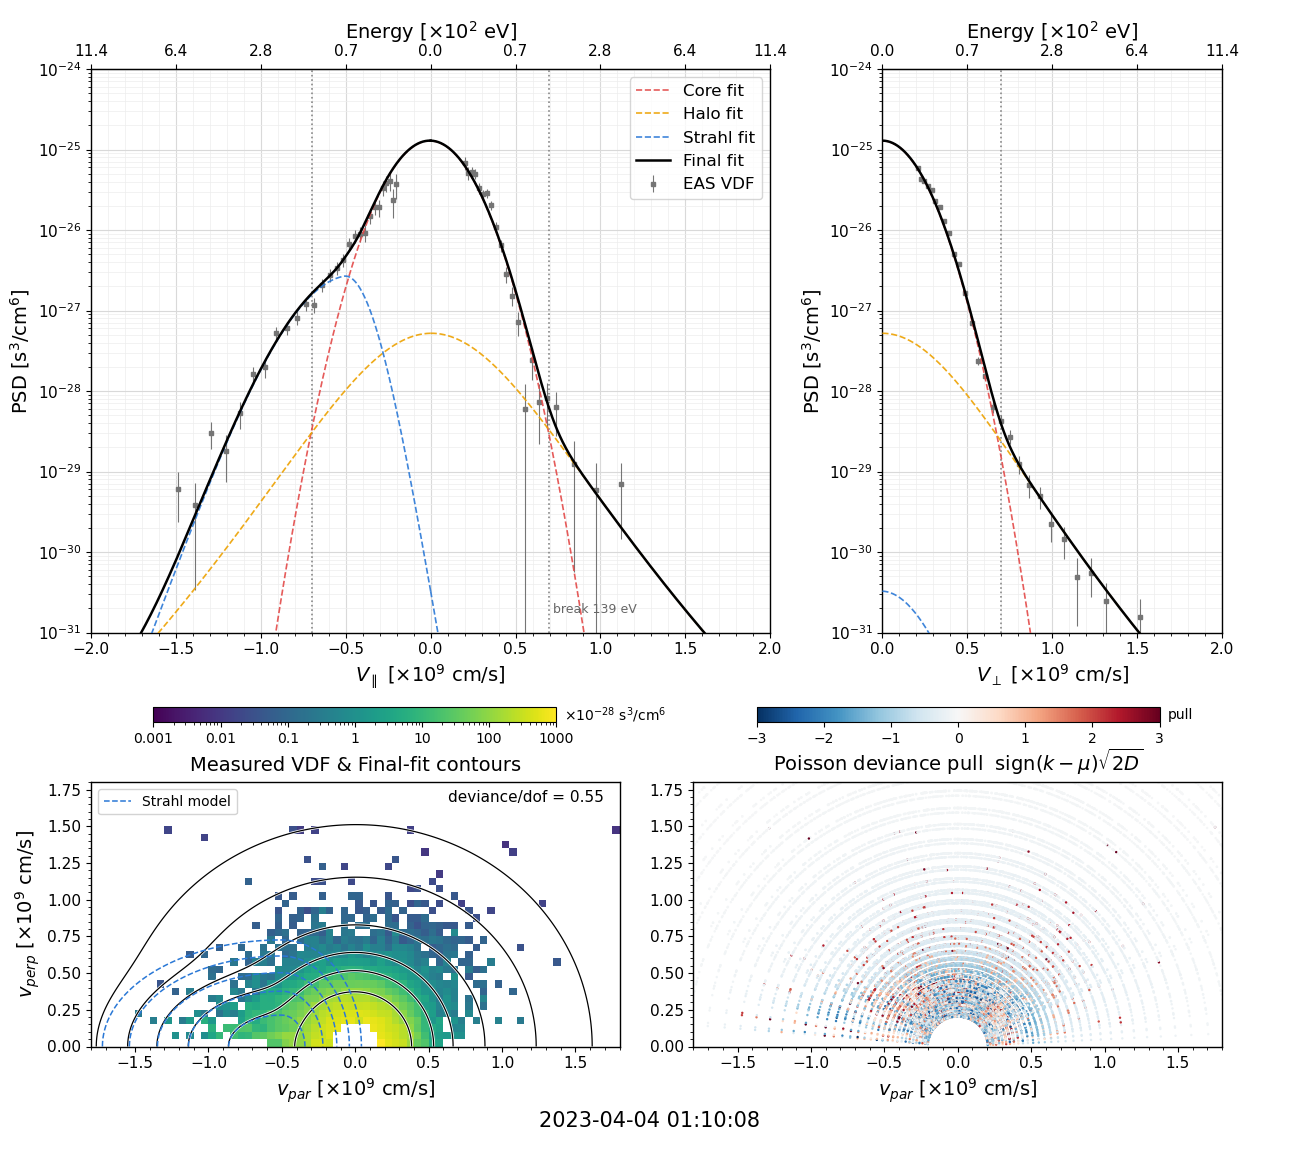

In [4]:
from IPython.display import Image

EPOCH = 20
figurePath = RESULTS_DIR / 'plots' / EXAMPLE_FILE.stem / f'epoch{EPOCH:04d}.png'
Image(filename=str(figurePath), width=900)

## Where to go next

- `01_eas_instrument_and_data.ipynb` - the instrument, its frames, what the data are
- `02_download_and_preprocess.ipynb` - from SOAR files to the fitting-ready file (pre-executed)
- `03_pad_strahl_and_break_energy.ipynb` - the two inputs measured before the fit
- `04_models_and_initial_guesses.ipynb` - the three models, their initial guesses and ranges
- `05_poisson_fit_step_by_step.ipynb` - the four stages and the goodness of fit, one epoch
- `06_batch_fit_and_two_days.ipynb` - many epochs, the output files, two full days
- `07_poisson_vs_chi2_low_counts.ipynb` - why Poisson and not chi-square
- `08_fit_quality_qc.ipynb` - quality flags that work at low counts